# Comment hours

Question: what time of day are fans most active? This is used to plan when VELORA posts Shorts.

I get the comment time from recent videos of each group. Comments in the first 48 hours after a video is posted are removed, because they only show when the video came out, not when fans are usually online.

Only the comment time is saved. No names or comment text.

In [11]:
import os
import time
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from googleapiclient.discovery import build
from googleapiclient.errors import HttpError

load_dotenv()
youtube = build("youtube", "v3", developerKey=os.getenv("YOUTUBE_API_KEY"))

## 1. Pick videos

For each group: the 10 newest Shorts and the 10 newest long videos, from the last year (at least 30 days old).

In [12]:
videos = pd.read_csv("../data/processed/videos_with_type.csv")
videos["published_at"] = pd.to_datetime(videos["published_at"])
videos = videos[videos["days_since"] <= 365]

picked = []
for group in videos["group"].unique():
    g = videos[videos["group"] == group].sort_values("published_at", ascending=False)
    picked.append(g[g["type"] == "Short"].head(50))
    picked.append(g[g["type"] != "Short"].head(50))

picked = pd.concat(picked)
print(len(picked), "videos")
picked.groupby("group").size()

432 videos


group
4EVE       100
ALALA       61
EMPRESS     25
FELIZZ      98
PiXXiE     100
VIIS        48
dtype: int64

## 2. Get comment times

Up to 200 comments per video (2 pages). 1 quota unit per page, so about 300 units in total.

Run this once. It saves the result, so next time you can skip to step 3.

In [13]:
def get_comment_times(video_id, max_pages=2):
    rows = []
    next_page = None

    for page in range(max_pages):
        try:
            res = youtube.commentThreads().list(
                part="snippet",
                videoId=video_id,
                maxResults=100,
                order="time",
                pageToken=next_page,
            ).execute()
        except HttpError:
            # comments are turned off for this video
            break

        for item in res["items"]:
            comment = item["snippet"]["topLevelComment"]["snippet"]
            rows.append({"video_id": video_id, "comment_at": comment["publishedAt"]})

        next_page = res.get("nextPageToken")
        if next_page is None:
            break

    return rows

In [14]:
all_comments = []

for i, video_id in enumerate(picked["video_id"]):
    all_comments.extend(get_comment_times(video_id))
    if i % 20 == 0:
        print(i, "videos done")
    time.sleep(0.2)

comments = pd.DataFrame(all_comments)
comments.to_csv("../data/raw/comment_times.csv", index=False)
print(len(comments), "comments saved")

0 videos done
20 videos done
40 videos done
60 videos done
80 videos done
100 videos done
120 videos done
140 videos done
160 videos done
180 videos done
200 videos done
220 videos done
240 videos done
260 videos done
280 videos done
300 videos done
320 videos done
340 videos done
360 videos done
380 videos done
400 videos done
420 videos done
8861 comments saved


## 3. Clean up

In [15]:
comments = pd.read_csv("../data/raw/comment_times.csv")
comments = comments.merge(picked[["video_id", "group", "type", "published_at"]], on="video_id")

comments["comment_at"] = pd.to_datetime(comments["comment_at"]).dt.tz_convert("Asia/Bangkok")
comments["hours_after"] = (comments["comment_at"] - comments["published_at"]).dt.total_seconds() / 3600

# remove the first 48 hours after release
comments = comments[comments["hours_after"] >= 48].copy()

comments["hour"] = comments["comment_at"].dt.hour
comments["day"] = comments["comment_at"].dt.day_name()

counts = comments["group"].value_counts()
keep = counts[counts >= 100].index
comments = comments[comments["group"].isin(keep)]

print(len(comments), "comments left")
comments["group"].value_counts()

2745 comments left


group
FELIZZ    1184
4EVE       682
PiXXiE     517
VIIS       362
Name: count, dtype: int64

## 4. Comments by hour (Thai time)

Each group counts the same, so a big group like 4EVE does not take over the result.

In [16]:
def hour_share(data):
    # % of comments in each hour, for each group
    by_group = pd.crosstab(data["group"], data["hour"], normalize="index") * 100
    by_group = by_group.reindex(columns=range(24), fill_value=0)
    # average of the groups
    return by_group.mean().round(2)


all_groups = hour_share(comments)
no_4eve = hour_share(comments[comments["group"] != "4EVE"])

hours = pd.DataFrame({"all_groups": all_groups, "without_4eve": no_4eve})
hours

,all_groups,without_4eve
hour,,
0,4.30,4.17
1,3.31,3.53
2,2.58,2.46
3,2.04,2.33
4,1.66,2.02
5,1.45,1.64
6,2.63,2.87
7,2.36,2.41
8,3.86,4.12


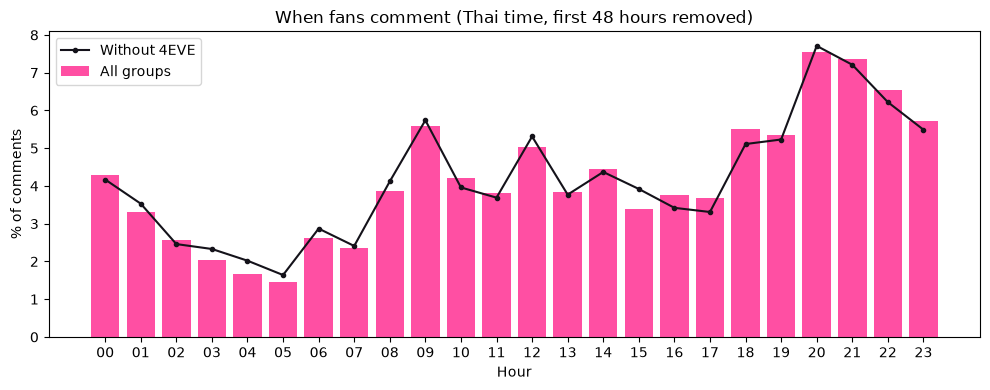

In [17]:
fig, ax = plt.subplots(figsize=(10, 4))
labels = [f"{h:02d}" for h in range(24)]

ax.bar(labels, hours["all_groups"], color="#FF4FA3", label="All groups")
ax.plot(labels, hours["without_4eve"], color="#14121A", marker="o", markersize=3, label="Without 4EVE")

ax.set_title("When fans comment (Thai time, first 48 hours removed)")
ax.set_xlabel("Hour")
ax.set_ylabel("% of comments")
ax.legend()
plt.tight_layout()
plt.savefig("../reports/figures/comment_hours.png", dpi=150)
plt.show()

In [18]:
print("Top 5 hours (all groups):")
print(hours["all_groups"].sort_values(ascending=False).head(5))
print()
print("Top 5 hours (without 4EVE):")
print(hours["without_4eve"].sort_values(ascending=False).head(5))

Top 5 hours (all groups):
hour
20    7.54
21    7.35
22    6.54
23    5.73
9     5.59
Name: all_groups, dtype: float64

Top 5 hours (without 4EVE):
hour
20    7.71
21    7.21
22    6.22
9     5.74
23    5.49
Name: without_4eve, dtype: float64


## 5. Peak hour of each group

Do all groups have the same busy time?

In [19]:
by_group = pd.crosstab(comments["group"], comments["hour"], normalize="index") * 100
by_group = by_group.reindex(columns=range(24), fill_value=0)

peak = pd.DataFrame({
    "peak_hour": by_group.idxmax(axis=1),
    "peak_share": by_group.max(axis=1).round(1),
    "comments": comments["group"].value_counts(),
})
peak

,peak_hour,peak_share,comments
group,,,
4EVE,21,7.8,682
FELIZZ,20,10.4,1184
PiXXiE,21,8.1,517
VIIS,9,8.6,362


## 6. Weekday vs weekend

In [20]:
comments["weekend"] = comments["day"].isin(["Saturday", "Sunday"])

week = pd.crosstab(comments["hour"], comments["weekend"], normalize="columns") * 100
week.columns = ["weekday", "weekend"]
week = week.reindex(range(24), fill_value=0).round(2)
week

,weekday,weekend
hour,,
0,3.84,5.04
1,3.23,3.28
2,2.82,2.14
3,1.79,3.03
4,1.64,1.39
5,1.69,1.51
6,2.61,3.03
7,2.46,2.77
8,3.64,2.40


## Findings

**Fans are most active from 20:00 to 22:00 (Thai time).**

- Busiest hours: 20:00 (7.5%), 21:00 (7.4%), 22:00 (6.5%). If comments were spread evenly, each hour would have about 4.2%
- 18:00-23:00 has 38% of all comments in only 6 hours (25% if evenly spread)
- **Same without 4EVE:** 20:00 (7.7%), 21:00 (7.2%), 22:00 (6.2%)
- **Same for most groups:** 4EVE, FELIZZ and PiXXiE peak at 20:00-21:00. VIIS is different (peak at 09:00)
- Smaller peaks at 09:00 (5.6%) and 12:00 (5.0%). Quietest time is 03:00-07:00
- **Weekday vs weekend:** weekdays have a sharp peak at 20:00 (8.9%). Weekends are flatter, with 18:00-23:00 all around 6-7%

**Decision for VELORA posting schedule:**
- **Main Shorts post: 19:30-20:00 on weekdays**, so the video is up before the 20:00-22:00 peak
- **Weekends: post around 18:00**, because fans are active earlier
- **Second post (optional): 12:00** for the lunch break peak
- This fits the MV plan (Thursday 19:00): the MV goes up one hour before the busiest time

**Limitations**
- Comment time is not the same as watch time. Many fans watch without commenting
- Some fans live outside Thailand, so their comment times are in a different time zone
- Only 4 groups have enough comments (100 or more). ALALA and EMPRESS have too few, and MXFRUIT and Pretzelle have no videos in the last year
- Up to 200 newest comments per video, from up to 100 videos per group